In [7]:

import numpy as np
import os
import nibabel as nib
import torch
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs


from cornucopia import RelabelTransform

from cornucopia.utils.py import meshgrid_ij
from cornucopia import (
    RandomGaussianMixtureTransform,
    GaussianNoiseTransform,
    ChiNoiseTransform,
    GammaNoiseTransform,
    GFactorTransform,
    RandomChiNoiseTransform,
    RandomMulFieldTransform,
)

In [8]:
def show_image(img, seg, title=None, subtitles=["MRI", "Labels"], figsize=(5, 5), vmin=None, vmax=None):
    plt.figure(figsize=figsize)
    plt.subplot(1, 2, 1)
    plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest', vmin=vmin, vmax=vmax)
    plt.axis('off')
    plt.title(subtitles[0])
    plt.subplot(1, 2, 2)
    plt.imshow(seg.squeeze(), cmap='tab20', interpolation='nearest', vmin=vmin, vmax=vmax)
    plt.axis('off')
    plt.title(subtitles[1])
    plt.show()

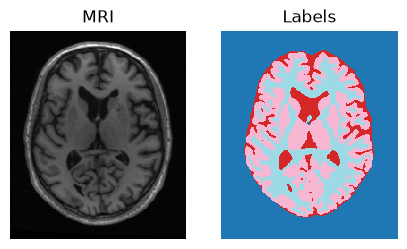

In [9]:
fname_img = "data/inputs/sub-ADNI002S0295_ses-m000_space-MNI_T1w.nii.gz"
fname_seg = "data/inputs/sub-ADNI002S0295_ses-m000_space-MNI_T1wdseg_synthsr.nii.gz"
# npz = np.load(fname)
# dat = torch.as_tensor(npz['vol'][:, :, 112]).T[None]
# lab = torch.as_tensor(npz['seg'][:, :, 112]).T[None]

seg = nib.load(fname_seg).get_fdata()
img = nib.load(fname_img).get_fdata()

thal = np.argwhere(np.isin(seg, [10, 49]))
cx, cy, cz = thal.mean(0).astype(int) if len(thal) else np.array(seg.shape) // 2

seg = ufs.merge_seg96_to_seg3(seg) #map to 0,1,2,3
dat = torch.as_tensor(np.flipud(img[:, :, cz].T).copy())[None]
lab = torch.as_tensor(np.flipud(seg[:, :, cz].T).copy())[None]

lab = RelabelTransform()(lab) #map to 0,1,2,3,...,N


show_image(dat, lab, title='MRI and Labels')

img = dat.clone()
# normalize the image to [0, 1]
img = (img - img.min()) / (img.max() - img.min())

[0 1 2 3]
[0.03116384 0.03910812 0.03979054 ... 0.85352707 0.8551293  0.85907924]


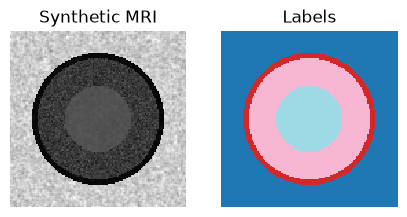

In [24]:
shape = [128, 128]
radius = torch.stack(meshgrid_ij(*[torch.arange(s).float() for s in shape]), -1)
radius -= (torch.as_tensor(shape).float() - 1) / 2
radius = radius.square().sum(-1).sqrt()

lab = torch.zeros_like(radius, dtype=torch.long)
lab[radius < 48] = 1
lab[radius < 44] = 2
lab[radius < 24] = 3
lab = lab[None]  # channel dimension

# we also generate an intenity image from this label map
img = RandomGaussianMixtureTransform(sigma=0.1)(lab)

# from cornucopia.random import Uniform
# gmm_mu: tuple = (0., 1.)          # tissue mean ~ U(0, 1)
# gmm_sigma: tuple = (0.001, 0.01)  # tissue std  ~ U(0.001, 0.01)
# img = RandomGaussianMixtureTransform(
#     mu=Uniform(gmm_mu),
#     sigma=Uniform(gmm_sigma),
#     fwhm=0,
#     background=0,
# )(lab)

print(np.unique(lab))
print(np.unique(img))

# plt.figure(figsize=(5, 5))
# plt.subplot(1, 2, 1)
# plt.imshow(lab.squeeze(), cmap='Set2', interpolation='nearest')
# plt.axis('off')
# plt.title('Labels')
# plt.subplot(1, 2, 2)
# plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest')
# plt.axis('off')
# plt.title('Intensity')
# plt.show()

show_image(img, lab, title='Synthetic MRI and Labels', subtitles=["Synthetic MRI", "Labels"])

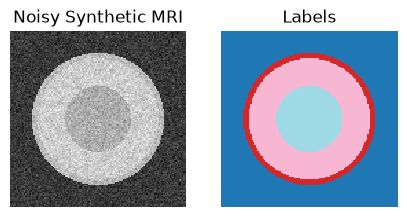

In [11]:
## Add noise to the image. the mean is each voxel value and the sigma is stablished in the transform
trf = GaussianNoiseTransform(sigma=0.1)
noisy = trf(img)

# plt.figure(figsize=(5, 5))
# plt.subplot(1, 2, 1)
# plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest', vmin=0, vmax=1)
# plt.axis('off')
# plt.title('Noise-free')
# plt.subplot(1, 2, 2)
# plt.imshow(noisy.squeeze(), cmap='gray', interpolation='nearest', vmin=0, vmax=1)
# plt.axis('off')
# plt.title('Noisy')
# plt.show()

show_image(noisy, lab, title='Synthetic MRI and Labels', subtitles=["Noisy Synthetic MRI", "Labels"])

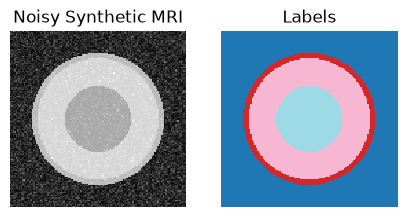

In [12]:
# chi noise is th one of MRI, rician noise is chi with 2 channels
trf = ChiNoiseTransform(sigma=0.1, nb_channels=2)
noisy = trf(img)


show_image(noisy, lab, title='Synthetic MRI and Labels', subtitles=["Noisy Synthetic MRI", "Labels"])

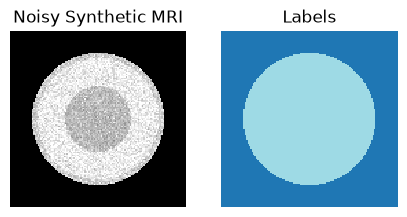

In [13]:
trf = GammaNoiseTransform()
noisy = trf(img)

show_image(noisy, lab, title='Synthetic MRI and Labels', subtitles=["Noisy Synthetic MRI", "Labels"], vmin=0, vmax=1)

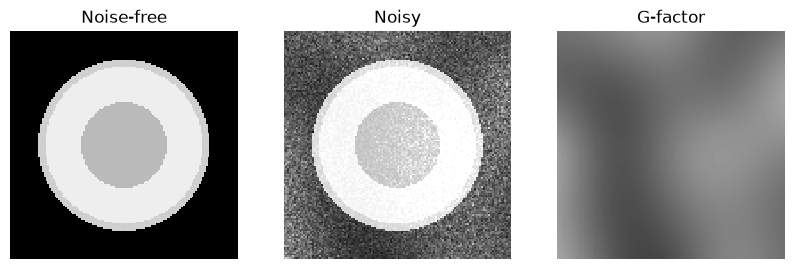

In [14]:
noise = ChiNoiseTransform(nb_channels=8)
gfactor = GFactorTransform(noise, returns=['output', 'gfactor'], shape=5, vmin=0, vmax=2, order=5)
noisy, gmap = gfactor(img)

plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest', vmin=0, vmax=1)
plt.axis('off')
plt.title('Noise-free')
plt.subplot(1, 3, 2)
plt.imshow(noisy.squeeze(), cmap='gray', interpolation='nearest', vmin=0, vmax=1)
plt.axis('off')
plt.title('Noisy')
plt.subplot(1, 3, 3)
plt.imshow(gmap.squeeze(), cmap='gray', interpolation='nearest', vmin=0, vmax=2)
plt.axis('off')
plt.title('G-factor')
plt.show()

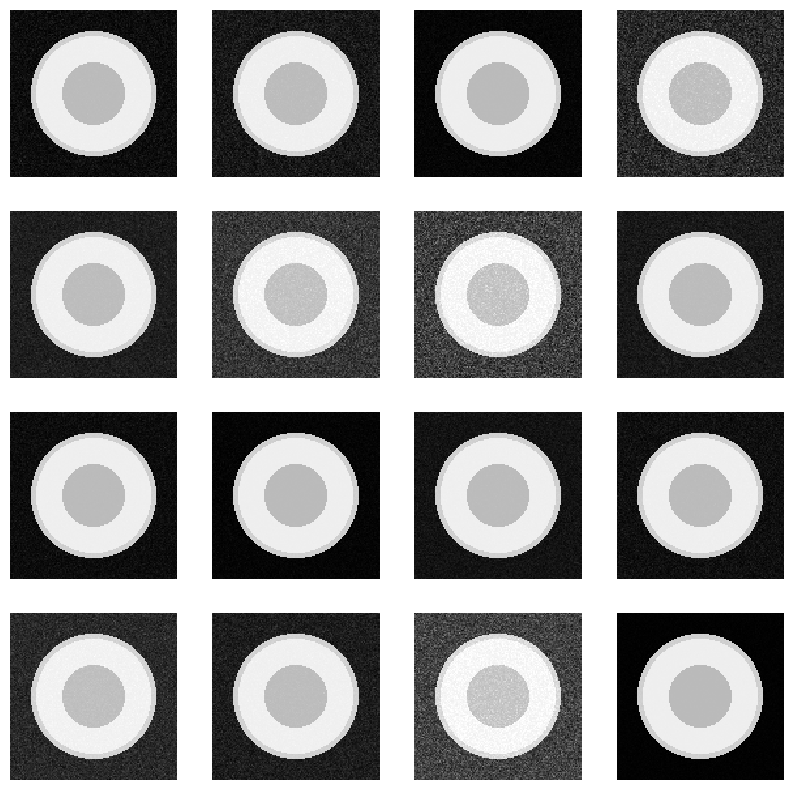

In [15]:
trf = RandomChiNoiseTransform()

shape = (4, 4)
plt.figure(figsize=(10, 10))
for i in range(shape[0]*shape[1]):
    noisy = trf(img)
    plt.subplot(*shape, i+1)
    plt.imshow(noisy.squeeze(), cmap='gray', interpolation='nearest', vmin=0, vmax=1)
    plt.axis('off')
plt.show()

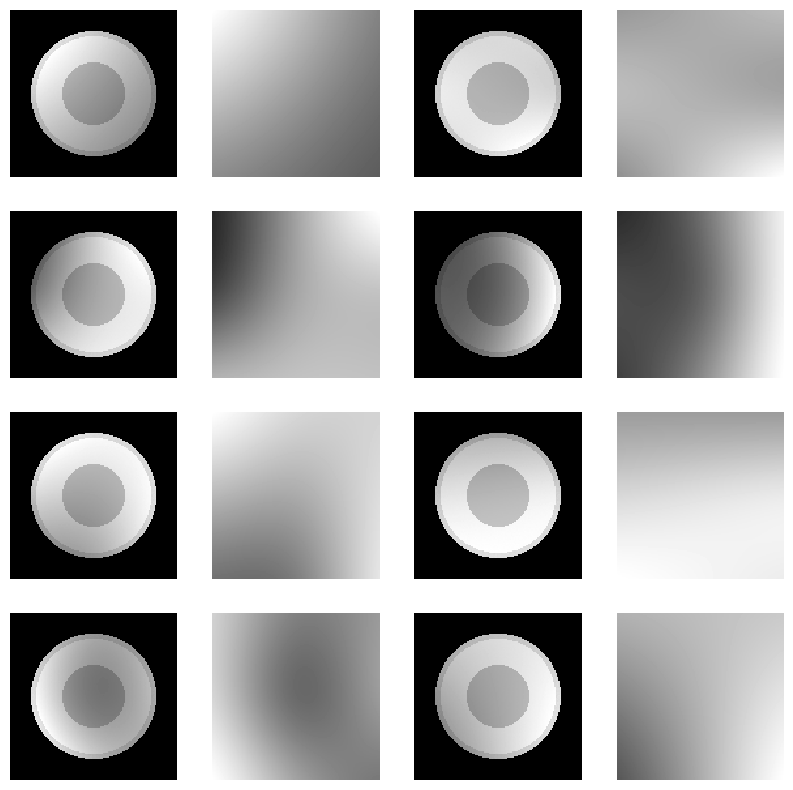

In [16]:
trf = RandomMulFieldTransform(returns=['output', 'field'], shape=3, symmetric=False)

shape = (4, 4)
plt.figure(figsize=(10, 10))
for i in range(shape[0]*shape[1]//2):
    modulated, field = trf(img)
    plt.subplot(*shape, 2*i+1)
    plt.imshow(modulated.squeeze(), cmap='gray', interpolation='nearest', vmin=0)
    plt.axis('off')
    plt.subplot(*shape, 2*i+2)
    plt.imshow(field.squeeze(), cmap='gray', interpolation='nearest', vmin=0)
    plt.axis('off')
plt.show()